#  Statistical Metamorphic Testing using the API

This intermediate-level tutorial demonstrates the Causal Testing Framework’s (CTF) core Python API, using statistical [metamorphic testing](https://en.wikipedia.org/wiki/Metamorphic_testing) as an example application. Assuming basic Python familiarity, it shows how to construct causal test cases that vary the sampling window dimensions of a Poisson Line Tessellation (PLT) model by customising the API. Theoretical background is in Section 5.1 of our [paper](https://dl.acm.org/doi/10.1145/3607184), with further resources at the end of the notebook.

The CTF requires three components to perform Causal Testing:
- a causal DAG
- causal test cases (which can be derived automatically from the DAG)
- data with which to evaluate the causal tests

The causal DAG encodes information about the expected causal structure of the system through nodes representing variables and directed edges representing causal relationships, which is a model of how the data could have been generated.

Read in the DAG and Data

At this point, it might be worthwhile to interrogate your data and apply any pre-processing, transforming or cleaning as necessary. However, for the purposes of this tutorial, there won't be any additional processing required. Section 5.13 of our [paper](https://dl.acm.org/doi/10.1145/3607184) explains in detail how this dataset was generated.

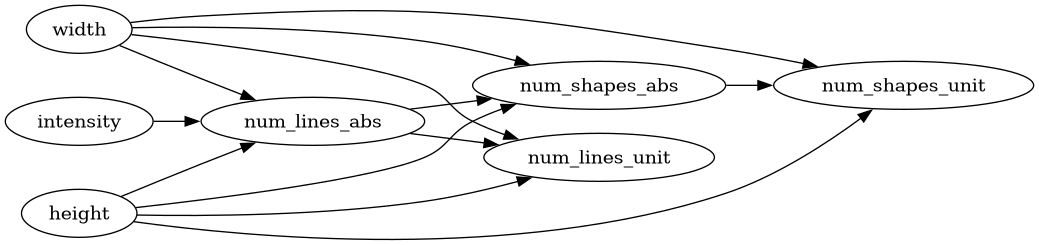

,width,height,intensity,num_lines_abs,num_shapes_abs,num_lines_unit,num_shapes_unit
0,4.908266,8.367783,10.684103,278,13991,6.768716,340.651464
1,9.239562,0.632306,12.826541,238,2603,40.737877,445.549133
2,5.144895,9.633530,15.219349,425,33859,8.574859,683.143879
3,3.489453,4.535775,8.362393,126,3305,7.960892,208.815469
4,7.985650,1.090290,1.032276,24,74,2.756506,8.499228
...,...,...,...,...,...,...,...
995,8.198583,2.479352,7.394970,152,3378,7.477674,166.181475
996,5.539523,9.453742,12.416852,378,22500,7.217980,429.641692
997,1.182998,4.851435,4.361107,53,534,9.234678,93.043734
998,2.438737,1.708604,1.107249,6,14,1.439942,3.359864


In [1]:
import pandas as pd
from causal_testing.specification.causal_dag import CausalDAG
import networkx as nx
from causal_testing.examples import poisson_line_process as plp
from IPython.display import Image, display


def render_dag(dag: CausalDAG):
    P = nx.nx_pydot.to_pydot(dag)
    P.set_node_defaults(shape="ellipse", style="filled", fillcolor="lightblue")
    P.set_graph_defaults(rankdir="LR")
    png_data = P.create_png(prog="dot")
    display(Image(png_data))

causal_dag = CausalDAG(plp.dag_path)
render_dag(causal_dag)

df = pd.read_csv(plp.data_path)
df

In this case, the PLT model has three positive floating-point input parameters: thee width and height of the sampling window, and the intensity of the Poisson process. The model then outputs the total number of lines intersecting the sampling window, and the number of polygons formed by the intersecting lines. Note: in this dataset, the output variables appended by the suffix `_unit` are normalised with respect to their respective areas (`width*height`).

## Step 3: Create Causal Test Cases

Now that we've created our Modelling Scenario, we're ready to create our Causal Tests. Causal tests are essentially metamorphic tests that are executed using statistical causal inference. A causal test expresses the change in a given output that we expect to see when we change a particular input in some way. 

Firstly, a `base test case`, which specifies the relationship between the given output and input and the desired effect, is required to build a `causal test case`. Together, the causal test case forms the complete executable test, which is the minimum required to perform identification on the DAG.

In this tutorial, the two metamorphic relations we would like to investigate are the following:

1. Doubling the intensity should cause the number of polygons per unit area to increase by a factor of 4.
2. The number of polygons per unit area should be independent of width and height.

### Metamorphic Relation 1: Doubling the intensity should cause the number of polygons per unit area to increase by a factor of 4

Following this, we can now create our causal test case. The minimum parameter's well need to create this are: the expected causal effect as a `CausalEffect` object (e.g. `ExactValue`), the estimate type, which is a `str` specifying the type of estimate to return, and an estimator, which can be is an `Estimator` object. Since the relation we're investigating is inherently linear, we can use the `LinearRegressionEstimator` class to build our causal test case.

In [2]:
import numpy as np
from causal_testing.estimation.linear_regression_estimator import LinearRegressionEstimator
from causal_testing.testing.causal_effect import ExactValue, Positive
from causal_testing.testing.causal_test_case import CausalTestCase

control_values, treatment_values = 2 ** np.arange(0, 4), 2 ** np.arange(1, 5) # Initialise the dummy intensity variables

intensity_results = [] # Initiate an empty list to store the causal test results

for (control, treatment) in zip(control_values, treatment_values): # Simultaneously loop over control and treatment
    
    estimator=LinearRegressionEstimator(
                    treatment_variable="intensity", # Our treatment variable
                    outcome_variable="num_shapes_unit", # Our outcome variable
                    treatment_value=treatment, # Doubled intensity values
                    control_value=control, # Baseline intensity values
                    formula="num_shapes_unit ~ I(intensity ** 2) + intensity - 1", # Patsy formula describing a linear regression model
                    alpha=0.05 # Significance level
    )
        
    causal_test_case = CausalTestCase(
                expected_causal_effect=ExactValue(4, atol=0.5), # Include a tolerence of 0.5
                effect_measure="risk_ratio", # As described in our paper
                estimator = estimator # Pass in the estimator we created above
    )


    causal_test_case.execute_test(df) # Execute the tests

    # Parse the test result values we need:
    intensity_results += [
        {
            "width": estimator.control_value,
            "height": estimator.treatment_value,
            "control": estimator.control_value,
            "treatment": estimator.treatment_value,
            "risk_ratio": causal_test_case.result.effect_estimate.effect_estimate[0],
        }]

Finally, we can parse the causal test results as a `pandas` dataframe and optionally export it to a `.csv` file.

In [3]:
intensity_results_df = pd.DataFrame(intensity_results)

intensity_results_df

,width,height,control,treatment,risk_ratio
0,1,2,1,2,2.827958
1,2,4,2,4,3.171104
2,4,8,4,8,3.477219
3,8,16,8,16,3.699311


#### Summary

From the above causal test results and the risk ratios, we can conclude that doubling the intensity does not cause the number of polygons per unit area to increase by a factor of 4 as we expected. Instead, it increases by factors ranging from 2.8 to 3.7, meaning that the metamorphic relation is violated at a 95% confidence level.

### Metamorphic Relation 2: The number of polygons per unit area should be independent of the width and height

In a very similar way to the method above, we can test our second metamorphic relation that the number of polygons per unit area should be independent of sample width and height. Since we are only interested in whether there is some effect, we use the average treatment effect (ATE) instead of the risk ratio from above, which quantifies the additive change in outcome caused by the intervention.

To investigate whether the width affects number of polygons per unit area, we need to execute a new set of test cases, but this time fixing the intensity and varying the width. Note: we don't need to redefine the modelling scenario, nor the perform identification again; but we have to redefine our base test case since we're now considering the Polygon's width as the treatment variable.

In [4]:
control_values, treatment_values = np.arange(1,10), np.arange(1, 17) # Initialise the dummy width variables

width_results = [] # Empty list for storing test case results 

for intensity in treatment_values:
   
  for width_value in control_values:
      
      estimator = LinearRegressionEstimator(
              treatment_variable="width", # Our treatment variable
              outcome_variable="num_shapes_unit", # Our outcome variable
              treatment_value = width_value + 1.0, # Changing the width
              control_value=float(width_value), # Baseline width values
              adjustment_config={"intensity": intensity},
              formula="num_shapes_unit ~ width + I(intensity ** 2)+I(width ** -1)+intensity-1", # Patsy formula describing a linear regression model
              alpha=0.05) # Significance level
      
      causal_test_case = CausalTestCase(
          expected_causal_effect = Positive(), # We expect a positive increase
          effect_measure = "ate_calculated", # Calls the ate_calculated method in the linear regression estimator
          estimator=estimator # Pass in the estimator we created above
      )
      
      causal_test_case.execute_test(df) # Execute the tests

      # Parse the test result values we need:
      width_results += [
           {
           "control": estimator.control_value,
           "treatment": estimator.treatment_value,
           "intensity": estimator.adjustment_config["intensity"],
           "ate": causal_test_case.result.effect_estimate.effect_estimate[0],
           "ci_low": causal_test_case.result.effect_estimate.ci_low[0],
           "ci_high": causal_test_case.result.effect_estimate.ci_high[0],
           }]


In [5]:
# Convert the results to a dataframe and print the first 10 rows

width_results_df = pd.DataFrame(width_results) 

width_results_df.head(10)

,control,treatment,intensity,ate,ci_low,ci_high
0,1.0,2.0,1,-7.378642,-13.918239,-0.839046
1,2.0,3.0,1,-2.709659,-9.802883,4.383566
2,3.0,4.0,1,-1.542413,-11.120888,8.036062
3,4.0,5.0,1,-1.075514,-13.708422,11.557393
4,5.0,6.0,1,-0.842065,-16.741294,15.057163
5,6.0,7.0,1,-0.708666,-19.972927,18.555596
6,7.0,8.0,1,-0.625291,-23.308418,22.057837
7,8.0,9.0,1,-0.569708,-26.704347,25.564931
8,9.0,10.0,1,-0.530800,-30.138282,29.076683
9,1.0,2.0,2,-7.378642,-16.381136,1.623851


## Summary

The causal test results in this case demonstrate that the ATE values for width increases from `1 → 2` through `9 → 10`, revealing that while most changes produce non-significant effects (ATEs ranging from `-2.7097` to `-0.5308` with confidence intervals containing zero), the width change from `1 → 2` produces a statistically significant negative effect of `-7.3786` with a confidence interval of `[-13.9182, -0.8390]`. This indicates that there is a problem with either the program or the metamorphic property itself. A likely interpretation is that, geometrically, lines are less likely to intersect a smaller sample window. As the sample window becomes larger, there is more area to average over. Therefore, the metamorphic relations should ideally specify a minimum window size to which they apply.

Additionally, in the paper we further demonstrate that these results show that the CTF was able to identify the same discrepancy as conventional statistical metamorphic testing, but using only a fifth of the data. Ultimately, this highlights the potential of causal inference-driven approaches to offer economical alternatives to testing techniques that depend on repeated potentially costly executions of the system under test.

## Additional Resources

- [GitHub Repository](https://github.com/CITCOM-project/CausalTestingFramework)
- [Documentation](https://causal-testing-framework.readthedocs.io/en/latest/index.html)
- [Paper](https://dl.acm.org/doi/10.1145/3607184)